# 04 · Der Chemie-Use-Case (dfthcsos) von innen

**Frage:** Was genau berechnet diese Aufgabe – und warum ist ihr Kern eine *Tabelle voller Winkel*?

Wir gehen den Weg vom Molekül bis zum Score und rechnen jeden Schritt **mit den echten Wettbewerbsdaten** nach:

| Teil | Thema | Was wir selbst rechnen |
|---|---|---|
| 1 | FeMoCo & die Energie-Frage | Die Integrale laden, N⁴-Problem sehen |
| 2 | Tensor-Faktorisierung (DF-THC) | `error_2` **von Hand** nachrechnen |
| 3 | Givens-Rotationen & Winkelwörter | Einen Vektor aus 75 Winkeln bauen; Bit-Genauigkeit vs. Fehler |
| 4 | λ, SOS-Shift, λ_eff | Warum der Shift den Score ~6× verbessert |
| 5 | Die Angle-Loader-Schaltkreise | Unsere Schaltkreise simulieren und prüfen |
| 6 | Score-Anatomie | Baseline vs. unsere Einreichung, Faktor 10,7× zerlegt |
| 7 | Hebel & Grenzen | Was wir gelernt haben |

Daten: offizieller Verifier `data/verifiers/dfthcsos`, Baseline `data/sample_submission/dfthcsos`, unsere Chemie aus qvc-007 (`work/frontier_scan/mwa2_unpacked/dfthcsos`, somejoint-Chemie-Record).

In [1]:
%pip install numpy matplotlib kickmix


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, time, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import kickmix as km

ROOT = Path.cwd().resolve()  # Repo-Root suchen (Notebook liegt in docs/learn/)
while not (ROOT / "data" / "verifiers").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
VER = ROOT / "data" / "verifiers"
sys.path.insert(0, str(VER))
from dfthcsos.verify import load_inputs, evaluate_words, verify, heuristic_costs
from dfthcsos.scoreinfra import dfthc_math as dm

BASE = ROOT / "data" / "sample_submission" / "dfthcsos"
OURS = ROOT / "work" / "frontier_scan" / "mwa2_unpacked" / "dfthcsos"
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.grid": True, "grid.alpha": .3})
print("Verifier:", VER.exists(), "| Baseline:", BASE.exists(), "| Unsere:", OURS.exists())

Verifier: True | Baseline: True | Unsere: True


## Teil 1 · FeMoCo und die Energie-Frage

**Hintergrund.** Ammoniak (NH₃) für Dünger entsteht industriell im Haber-Bosch-Verfahren (≈ 400 °C, 200 bar) – das verbraucht ~2 % der Weltenergie. Bakterien schaffen dasselbe bei Raumtemperatur mit dem Enzym *Nitrogenase*; dessen aktives Zentrum ist der Eisen-Molybdän-Cluster **FeMoCo**. Wie er N₂ spaltet, ist unbekannt, weil seine Elektronen stark korreliert sind – klassische Methoden scheitern daran.

**Die Rechenaufgabe:** Die **Grundzustandsenergie** E₀ des Elektronensystems bestimmen. Wer E₀ (und Energien verschiedener Zwischenzustände) genau kennt, kann Reaktionswege vergleichen.

**Das Modell** (Quantenchemie, „zweite Quantisierung“): Man wählt N = 76 räumliche Orbitale mit η = 113 Elektronen. Der Hamiltonoperator ist

$$H = E_\text{core} + \sum_{pq} h_{pq}\,E_{pq} + \tfrac12 \sum_{pqrs} (pq|rs)\,E_{pq}E_{rs}$$

- `h_pq` (*oei*): Ein-Elektron-Integrale – kinetische Energie + Anziehung durch Kerne. 76×76 Zahlen.
- `(pq|rs)` (*tei*): Zwei-Elektron-Integrale – Abstoßung zwischen Elektronen. **76⁴ ≈ 33 Mio. Zahlen.**
- Einheit: Hartree (Ha). 1 Ha ≈ 27,2 eV; „chemische Genauigkeit“ ≈ 1,6 mHa.

Diese Zahlen stehen in der FCIDUMP-Datei. Laden wir sie:

In [3]:
t = time.time()
inp = load_inputs(str(OURS / "submission.npz"))      # lädt Faktorisierung + Referenzintegrale (SHA-geprüft)
ref = inp.ref
print(f"geladen in {time.time()-t:.1f} s")
oei, tei = ref["oei"], ref["tei"]
N, eta = oei.shape[0], ref["electrons"]
print(f"N = {N} Orbitale, η = {eta} Elektronen, E_core = {ref['ecore']:.4f} Ha")
print(f"E_upper (Referenz-Energie, obere Schranke) = {inp.energy_upper} Ha")
print(f"oei: {oei.shape}   tei: {tei.shape} = {tei.size:,} Einträge ({tei.nbytes/1e6:.0f} MB)")

# 8-fache Symmetrie der Zwei-Elektron-Integrale: (pq|rs) = (qp|rs) = (pq|sr) = (rs|pq) ...
sym = [np.allclose(tei, tei.transpose(*p)) for p in [(1,0,2,3), (0,1,3,2), (2,3,0,1)]]
print("Symmetrien (qp|rs), (pq|sr), (rs|pq):", sym)
n_pairs = N * (N + 1) // 2
print(f"→ eindeutige Einträge ≈ {n_pairs*(n_pairs+1)//2:,}  (immer noch O(N⁴/8))")

geladen in 7.3 s
N = 76 Orbitale, η = 113 Elektronen, E_core = -21021.2140 Ha
E_upper (Referenz-Energie, obere Schranke) = -22140.27335 Ha
oei: (76, 76)   tei: (76, 76, 76, 76) = 33,362,176 Einträge (267 MB)
Symmetrien (qp|rs), (pq|sr), (rs|pq): [True, True, True]
→ eindeutige Einträge ≈ 4,282,201  (immer noch O(N⁴/8))


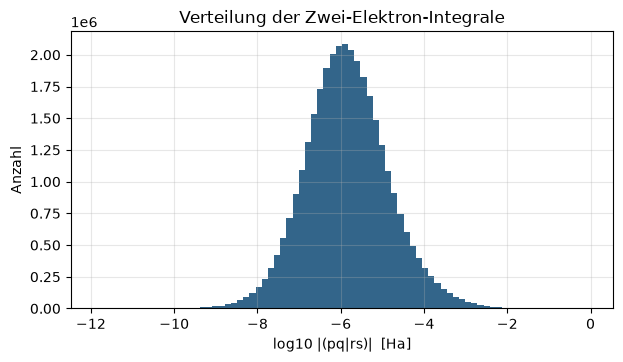

|(pq|rs)| > 0.1 Ha:   0.0 % der Einträge
|(pq|rs)| > 0.01 Ha:   0.0 % der Einträge
|(pq|rs)| > 0.001 Ha:   0.5 % der Einträge
|(pq|rs)| > 0.0001 Ha:   3.9 % der Einträge


In [4]:
a = np.abs(tei).ravel()
fig, ax = plt.subplots()
ax.hist(np.log10(a[a > 1e-12]), bins=80, color="#33658a")
ax.set(xlabel="log10 |(pq|rs)|  [Ha]", ylabel="Anzahl", title="Verteilung der Zwei-Elektron-Integrale")
plt.show()
for thr in [1e-1, 1e-2, 1e-3, 1e-4]:
    print(f"|(pq|rs)| > {thr:g} Ha: {np.mean(a > thr)*100:5.1f} % der Einträge")

**Das Problem:** Ein Quantencomputer misst E₀ per *Phasenschätzung*. Dafür muss er `H` als **Linearkombination von Unitären** (LCU) einbetten: `H = Σ_k α_k U_k`. Die Zahl der Wiederholungen ist ∝ **λ = Σ|α_k|** (die *Normierung*) geteilt durch die Zielgenauigkeit – und jede Wiederholung muss die Koeffizienten aus einer Tabelle laden.

Naiv hieße das: ~4 Mio. Koeffizienten pro Wiederholung laden, und λ wäre riesig. Die Lösung des Wettbewerbs: **die Integrale vorher klassisch komprimieren.**

## Teil 2 · Tensor-Faktorisierung (DF-THC): 33 Mio. Zahlen → wenige Vektoren

Die Idee (*Double-Factorized Tensor Hypercontraction*): Schreibe den N⁴-Tensor als Summe von Produkten kleiner Matrizen, und jede Matrix als gewichtete Summe von **Rang-1-Bausteinen** `u uᵀ`:

$$X^{(\rho c)} = \sum_{b=1}^{B} w_b^{(\rho c)}\; u_b^{(\rho)} u_b^{(\rho)\,T}
\qquad\qquad
(pq|rs) \;\approx\; \sum_{\rho=1}^{R}\sum_{c=1}^{C} X^{(\rho c)}_{pq}\, X^{(\rho c)}_{rs} \;-\; \text{Shift}(S)$$

| Symbol | Bedeutung | Baseline | Unsere |
|---|---|---|---|
| R | Anzahl „Gruppen“ ρ | 65 | 9 |
| B | Einheitsvektoren `u_b^(ρ)` pro Gruppe (je 76 Einträge, Norm 1) | 60 | 143 |
| C | Gewichtssätze pro Gruppe (wie oft die Vektoren neu kombiniert werden) | 60 | 39 |

**Analogie:** Wie eine SVD/Low-Rank-Zerlegung im Machine Learning oder JPEG – man behält nur die Struktur, die den Tensor trägt. Regel: Die Abweichung `error_2` (Frobenius-Norm über alle 33 Mio. Einträge) muss **≤ 20 mHa** bleiben.

Wichtig für die Quantenhardware: Der Quantencomputer muss **nur die R·B Einheitsvektoren** (und 76 Ein-Elektron-Vektoren) laden – die Gewichte `w` stecken in der Zustandspräparation.

In [5]:
def form(npz):
    z = np.load(npz)
    R, B, C = z["W"].shape          # Achtung Namens-Falle: npz "W" = kleine Gewichte w (R,B,C), "H2_I" = große W (R,C)
    return dict(R=R, B=B, C=C, Zeilen=N + R * B,
                Parameter=R * B * N + R * B * C + R * C,
                Kompression=f"{tei.size / (R*B*N + R*B*C + R*C):.0f}×")

for name, d in [("Baseline", BASE), ("Unsere ", OURS)]:
    print(name, form(d / "submission.npz"))

Baseline {'R': 65, 'B': 60, 'C': 60, 'Zeilen': 3976, 'Parameter': 534300, 'Kompression': '62×'}
Unsere  {'R': 9, 'B': 143, 'C': 39, 'Zeilen': 1363, 'Parameter': 148356, 'Kompression': '225×'}


**Auffällig:** Unsere Faktorisierung nutzt nur **R = 9 Gruppen** mit dafür **B = 143 Vektoren** pro Gruppe – also 1.363 statt 3.976 Tabellenzeilen. Weniger Zeilen = kleinere Lookup-Tabellen = weniger Toffolis (Teil 5). Das ist eine Designentscheidung, die erst im Zusammenspiel mit den Schaltkreisen Sinn ergibt.

Jetzt rechnen wir `error_2` **selbst nach** – exakt wie der Verifier, aber Schritt für Schritt. Die Vektoren holen wir aus den Winkelwörtern, die unsere Schaltkreise laden (wie das Dekodieren funktioniert, kommt in Teil 3).

In [6]:
z_ours = np.load(OURS / "submission.npz")
words, edges, brot = z_ours["angle_words"], z_ours["tree_edges"], int(z_ours["brot"])
w_small, W_big, S = inp.w, inp.W, inp.S                # (R,B,C), (R,C), (N,N)
R, B, C = w_small.shape

# 1) Winkelwörter → Einheitsvektoren (Teil 3 erklärt das)
vectors = dm.reconstruct_u_vectors(words / 2 ** (brot - 1), edges)
u = vectors[N:].reshape(R, B, N)                       # die R·B Zwei-Elektron-Vektoren

# 2) X^(ρc) = Σ_b w_b u_b u_bᵀ    (R, C, N, N)
X = np.einsum("rbc,rbp,rbq->rcpq", w_small, u, u, optimize=True)
X = np.tril(X) + np.swapaxes(np.tril(X, k=-1), -1, -2)  # wie der Verifier: aus dem unteren Dreieck symmetrisieren

# 3) Tensor zurückbauen und mit den echten Integralen vergleichen
t = time.time()
h2 = np.einsum("rcpq,rcst->pqst", X, X, optimize=True)
d = np.arange(N)
h2[:, :, d, d] -= 0.5 * S[:, :, None]                  # Teilchenzahl-Shift (S ⊗ I + I ⊗ S)/2
h2[d, d, :, :] -= 0.5 * S[None, :, :]
err2 = np.linalg.norm((h2 - tei).ravel())
print(f"error_2 von Hand = {err2*1000:.6f} mHa   ({time.time()-t:.1f} s)")

m_ours = evaluate_words(inp, words, edges, brot)
print(f"error_2 Verifier = {m_ours['error_2']*1000:.6f} mHa   Grenze: 20 mHa")
print(f"Abstand zur Grenze: {(0.020 - m_ours['error_2'])*1e3*1e6:.2f} nHa  ← extrem knapp, absichtlich ausgereizt")
del h2

error_2 von Hand = 19.999650 mHa   (0.2 s)
error_2 Verifier = 19.999650 mHa   Grenze: 20 mHa
Abstand zur Grenze: 349.97 nHa  ← extrem knapp, absichtlich ausgereizt


**Was das zeigt:** Die 1.287 Vektoren × Gewichte rekonstruieren 33 Mio. Integrale bis auf 20 mHa (Frobenius über *alle* Einträge). Und unsere Einreichung liegt nur **Nano-Hartree** unter der Grenze – jeder Fehlerspielraum wurde in Kompression umgewandelt. Genau deshalb ist dieser Task so empfindlich: Ein einziges zusätzliches Rundungsbit weniger, und die Einreichung fällt durch.

## Teil 3 · Givens-Rotationen: ein Vektor aus 75 Winkeln

Ein Einheitsvektor in 76 Dimensionen hat 75 Freiheitsgrade. Man kann ihn darum als **Folge von 75 Drehungen** in 2D-Ebenen (*Givens-Rotationen*) schreiben, die bei `e₀ = (1, 0, …, 0)` starten:

```
v = e_0
für jede Kante t = (Eltern p, Kind c) im Baum:
    θ_t = π · word_t / 2^(brot−1)
    (v_p, v_c) ← (cos θ·v_p − sin θ·v_c,  sin θ·v_p + cos θ·v_c)
```

Auf dem Quantencomputer ist das wörtlich so: Jede Givens-Rotation dreht die Amplitude zwischen zwei Orbitalen. Die **Kanten bilden einen Baum** (`tree_edges`), Wurzel = Orbital 0. Die Winkel werden als `brot`-Bit-Ganzzahlen („Winkelwörter“) gespeichert – **diese Wörter sind es, die die Angle-Loader-Schaltkreise laden.**

erste 10 Baumkanten (Eltern → Kind): [(np.int64(0), np.int64(1)), (np.int64(0), np.int64(2)), (np.int64(1), np.int64(3)), (np.int64(0), np.int64(4)), (np.int64(2), np.int64(6)), (np.int64(1), np.int64(5)), (np.int64(3), np.int64(7)), (np.int64(0), np.int64(8)), (np.int64(4), np.int64(12)), (np.int64(2), np.int64(10))]
Baumtiefe: 6  (Pfad wäre 75, Log-Tiefe ~7)

Zeile 76: erste 6 Wörter [np.int64(43), np.int64(37), np.int64(30), np.int64(253), np.int64(10), np.int64(2)]  →  θ/π = [0.3359 0.2891 0.2344 1.9766 0.0781 0.0156]
Norm des dekodierten Vektors: 1.000000000000  (immer exakt 1 – Drehungen erhalten die Länge)
Überlapp mit dem unquantisierten Vektor aus U: |⟨v|u⟩| = 1.000000


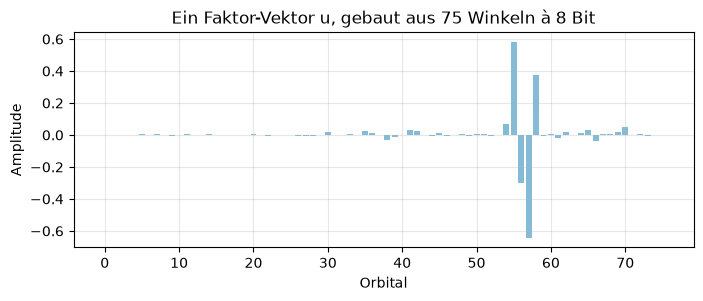

In [7]:
print("erste 10 Baumkanten (Eltern → Kind):", [tuple(e) for e in edges[:10]])
depth = {0: 0}
for p, c in edges:
    depth[int(c)] = depth[int(p)] + 1
print(f"Baumtiefe: {max(depth.values())}  (Pfad wäre 75, Log-Tiefe ~7)")

row = N                                             # erste Zwei-Elektron-Zeile = u_1^(1)
theta = words[row] / 2 ** (brot - 1)                # in Einheiten von π
v = dm.reconstruct_u_vectors(theta[None, :], edges)[0]
print(f"\nZeile {row}: erste 6 Wörter {list(words[row,:6])}  →  θ/π = {np.round(theta[:6], 4)}")
print(f"Norm des dekodierten Vektors: {np.linalg.norm(v):.12f}  (immer exakt 1 – Drehungen erhalten die Länge)")

u_float = z_ours["U"][0, 0] / np.linalg.norm(z_ours["U"][0, 0])
print(f"Überlapp mit dem unquantisierten Vektor aus U: |⟨v|u⟩| = {abs(v @ u_float):.6f}")

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(range(N), v, color="#86bbd8")
ax.set(xlabel="Orbital", ylabel="Amplitude", title=f"Ein Faktor-Vektor u, gebaut aus 75 Winkeln à {brot} Bit")
plt.show()

### Experiment: Wie viele Bits braucht ein Winkel?

Weniger Bits pro Winkel = schmalere Wortregister (weniger Qubits, kleinere Loader) – aber gröbere Vektoren, also größerer Fehler. Wir nehmen die **Baseline** (12-Bit-Wörter) und runden sie auf 11, 10, … 6 Bit ab:

12 Bit: error_1 =    3.19 mHa   error_2 =   18.64 mHa   λ_eff = 49.301   OK
11 Bit: error_1 =   76.91 mHa   error_2 =   29.72 mHa   λ_eff = 49.403   ABGELEHNT
10 Bit: error_1 =  133.49 mHa   error_2 =   43.82 mHa   λ_eff = 49.610   ABGELEHNT
 9 Bit: error_1 =  262.08 mHa   error_2 =   78.71 mHa   λ_eff = 50.768   ABGELEHNT
 8 Bit: error_1 =  541.08 mHa   error_2 =  156.65 mHa   λ_eff = 54.519   ABGELEHNT
 7 Bit: error_1 = 1100.40 mHa   error_2 =  300.01 mHa   λ_eff = 62.128   ABGELEHNT
 6 Bit: error_1 = 2374.22 mHa   error_2 =  595.23 mHa   λ_eff = 82.665   ABGELEHNT


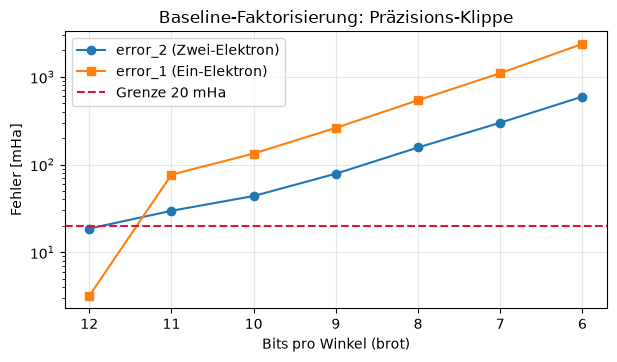

In [8]:
inp_base = load_inputs(str(BASE / "submission.npz"))
zb = np.load(BASE / "submission.npz")
wb, eb = zb["angle_words"], zb["tree_edges"]

def runde(w, von, nach):
    return np.rint(w / 2 ** (von - nach)).astype(np.int64) % (2 ** nach)

rows = []
for bits in range(12, 5, -1):
    m = evaluate_words(inp_base, runde(wb, 12, bits), eb, bits)
    rows.append((bits, m["error_1"] * 1e3, m["error_2"] * 1e3, m["lambda_eff"]))
    print(f"{bits:2d} Bit: error_1 = {m['error_1']*1e3:7.2f} mHa   error_2 = {m['error_2']*1e3:7.2f} mHa   "
          f"λ_eff = {m['lambda_eff']:.3f}   {'OK' if max(m['error_1'], m['error_2']) <= 0.02 else 'ABGELEHNT'}")

r = np.array(rows)
fig, ax = plt.subplots()
ax.semilogy(r[:, 0], r[:, 2], "o-", label="error_2 (Zwei-Elektron)")
ax.semilogy(r[:, 0], r[:, 1], "s-", label="error_1 (Ein-Elektron)")
ax.axhline(20, color="crimson", ls="--", label="Grenze 20 mHa")
ax.set(xlabel="Bits pro Winkel (brot)", ylabel="Fehler [mHa]", title="Baseline-Faktorisierung: Präzisions-Klippe")
ax.invert_xaxis(); ax.legend(); plt.show()

**Lesart:** Die Baseline-Faktorisierung verträgt **kein einziges Bit weniger** – schon bei 11 Bit kippt vor allem `error_1` (Ein-Elektron-Teil) weit über 20 mHa, und λ_eff steigt mit gröberen Winkeln. Unsere Einreichung erreicht **8 Bit** nur, weil die Faktorisierung *gemeinsam mit der Quantisierung* optimiert wurde (Gewichte so nachgefittet, dass die gerundeten Vektoren gut passen). Gegenprobe – unsere 8-Bit-Wörter auf 7 Bit gerundet:

In [9]:
m7 = evaluate_words(inp, runde(words, 8, 7), edges, 7)
print(f"unsere Wörter, 8 Bit: error_2 = {m_ours['error_2']*1e3:.4f} mHa  → OK")
print(f"unsere Wörter, 7 Bit: error_2 = {m7['error_2']*1e3:.2f} mHa  → {'OK' if m7['error_2'] <= .02 else 'ABGELEHNT'}")

unsere Wörter, 8 Bit: error_2 = 19.9997 mHa  → OK
unsere Wörter, 7 Bit: error_2 = 425.35 mHa  → ABGELEHNT


## Teil 4 · Normierung λ, SOS-Shift und λ_eff

Die Zahl der Phasenschätzungs-Schritte skaliert mit der LCU-Normierung. Für DF-THC:

$$\Lambda = \underbrace{\sum_j |\lambda_j|}_{\text{Ein-Elektron (Eigenwerte von } h')} \;+\; \underbrace{\tfrac14 \sum_{\rho c}\Big(|w_B^{(\rho c)}| + \sum_b |w_b^{(\rho c)}|\Big)^2}_{\text{Zwei-Elektron}}$$

**Der Trick: Sum-of-Squares (SOS).** Die Faktorisierung ist eine Summe von *Quadraten* (`X ⊗ X`), also ein positiver Operator. Daraus folgt eine garantierte **untere Schranke** `E_SOS ≤ E₀`. Kennt man außerdem eine obere Schranke `E_upper ≥ E₀`, liegt das Spektrum, das wirklich interessiert, in einem schmalen Fenster der Breite

$$E_\text{gap} = E_\text{upper} - E_\text{SOS}.$$

*Spektrale Verstärkung* nutzt das aus: Statt Λ zählt nur noch

$$\lambda_\text{eff} = \sqrt{E_\text{gap}\,(2\Lambda - E_\text{gap})} \;\approx\; \sqrt{2\Lambda\,E_\text{gap}}.$$

Weil `E_gap` (≈ 4 Ha) viel kleiner ist als Λ (≈ 300 Ha), ist λ_eff viel kleiner als Λ.

Baseline: Λ =  308.46 Ha  (Ein-El.  12.88 + Zwei-El. 295.58)   E_SOS = -22144.239   E_gap = 3.965477 Ha   λ_eff = 49.301   → Gewinn Λ/λ_eff = 6.3×
Unsere : Λ =  284.39 Ha  (Ein-El.  13.13 + Zwei-El. 271.26)   E_SOS = -22144.188   E_gap = 3.914899 Ha   λ_eff = 47.026   → Gewinn Λ/λ_eff = 6.0×

Untergrenzen (gegen Tricksen): Λ > 49.0,  E_gap > 3.914898
Unser Abstand zur E_gap-Grenze: 0.001 mHa


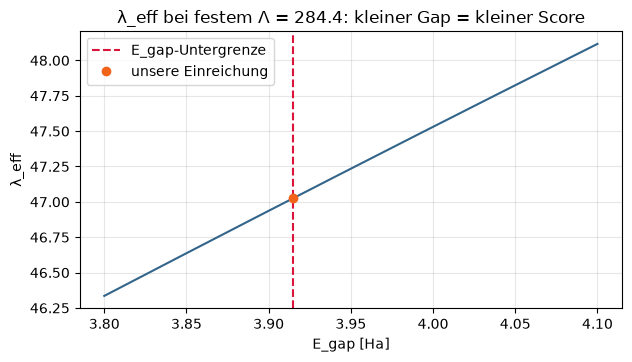

In [10]:
lam_h2 = dm.lambda_h2(inp.w, inp.W)
for name, m, lh2 in [("Baseline", evaluate_words(inp_base, wb, eb, 12), dm.lambda_h2(inp_base.w, inp_base.W)),
                     ("Unsere ", m_ours, lam_h2)]:
    print(f"{name}: Λ = {m['Lambda']:7.2f} Ha  (Ein-El. {m['Lambda']-lh2:6.2f} + Zwei-El. {lh2:6.2f})   "
          f"E_SOS = {m['E_SOS']:.3f}   E_gap = {m['E_gap']:.6f} Ha   λ_eff = {m['lambda_eff']:.3f}   "
          f"→ Gewinn Λ/λ_eff = {m['Lambda']/m['lambda_eff']:.1f}×")

GAP_FLOOR, LAMBDA_FLOOR = 3.914898, 49.0
print(f"\nUntergrenzen (gegen Tricksen): Λ > {LAMBDA_FLOOR},  E_gap > {GAP_FLOOR}")
print(f"Unser Abstand zur E_gap-Grenze: {(m_ours['E_gap']-GAP_FLOOR)*1e3:.3f} mHa")

L = m_ours["Lambda"]
g = np.linspace(3.80, 4.10, 300)
fig, ax = plt.subplots()
ax.plot(g, np.sqrt(g * (2 * L - g)), color="#33658a")
ax.axvline(GAP_FLOOR, color="crimson", ls="--", label="E_gap-Untergrenze")
ax.plot(m_ours["E_gap"], m_ours["lambda_eff"], "o", color="#f26419", label="unsere Einreichung")
ax.set(xlabel="E_gap [Ha]", ylabel="λ_eff", title=f"λ_eff bei festem Λ = {L:.1f}: kleiner Gap = kleiner Score")
ax.legend(); plt.show()

**Konsequenz:** Man möchte `E_gap` so klein wie möglich – also `E_SOS` so hoch wie möglich (straffere Schranke). Das Wettbewerbs-Floor `E_gap > 3,914898 Ha` verhindert, dass man das bis zur Absurdität treibt. Unsere Einreichung sitzt **knapp über dem Floor** – auch dieser Hebel ist ausgereizt.

## Teil 5 · Die Angle-Loader-Schaltkreise: der Teil, den wir *bauen*

Während eines Block-Encoding-Schritts steht im Register `selection` die Adresse `a` einer Tabellenzeile (welcher Vektor gerade dran ist – in Überlagerung über alle Zeilen). Die **75 Winkelwörter dieser Zeile** müssen in Wortregister geladen werden, damit die Givens-Schaltung sie als Drehwinkel verwenden kann.

Weil nur `J` Wortregister existieren, wird gestreamt: 75 Wörter → `K = ⌈75/J⌉` Pakete. Schaltkreis `k` ist ein XOR-Orakel:

```
ANGLE_k: |a⟩|z⟩ → |a⟩|z ⊕ delta[k,a]⟩     mit  delta[k,a] = Paket_k(a) ⊕ Paket_{k−1}(a)
```

Nacheinander angewendet steht nach Schaltkreis k genau Paket k in den Registern; rückwärts angewendet wird alles wieder 0. **Regeln:** Hilfsqubits enden auf 0, keine Phase (nur HMR-Korrekturen erlaubt), **≤ 128 Qubits pro Schaltkreis**, keine `Z_POW`.

In [11]:
fam = [km.Circuit.from_file(str(OURS / f"angle_k_{k}.kmb")) for k in range(15)]
regs = {k: len(v) for k, v in fam[0].register_data.items()}
J = sum(1 for k in regs if k.startswith("word_"))
print("Register:", regs, f"→ J = {J} Wörter à {brot} Bit, K = {len(fam)} Schaltkreise")

def lade_familie(circuits, adressen, J, seed=0):
    # Familie vorwärts laufen lassen, nach jedem Schaltkreis die Wortregister lesen; dann rückwärts.
    sim = km.Simulator(batch_size=len(adressen), seed=seed, debug_print=False)
    sim.use_same_registers_as(circuits[0])
    for s, a in enumerate(adressen):
        sim.write_within_shot("selection", s, int(a))
    pakete = []
    for c in circuits:
        sim.do(c)
        pakete.append([[sim.read_within_shot(f"word_{j}", s, out=int) for j in range(J)] for s in range(len(adressen))])
        assert all(sim.read_shot_phase(s) == 0 for s in range(len(adressen))), "Phasenfehler!"
    for c in reversed(circuits):
        sim.do(c)                                       # XOR-Orakel sind selbstinvers
    leer = all(sim.read_within_shot(f"word_{j}", s, out=int) == 0 for j in range(J) for s in range(len(adressen)))
    return np.array(pakete), leer                       # pakete: (K, shots, J)

rng = np.random.default_rng(0)
adressen = np.concatenate([[0, 75, 76, len(words) - 1], rng.integers(0, len(words), 60)])
pakete, leer = lade_familie(fam, adressen, J)
geladen = pakete.transpose(1, 0, 2).reshape(len(adressen), -1)[:, :75]
print(f"{len(adressen)} Adressen: alle 75 Wörter korrekt geladen: {np.array_equal(geladen, words[adressen])}")
print(f"Rückwärtslauf leert alle Wortregister: {leer}")

Register: {'selection': 11, 'word_0': 8, 'word_1': 8, 'word_2': 8, 'word_3': 8, 'word_4': 8} → J = 5 Wörter à 8 Bit, K = 15 Schaltkreise
64 Adressen: alle 75 Wörter korrekt geladen: True
Rückwärtslauf leert alle Wortregister: True


In [12]:
fam_base = [km.Circuit.from_file(str(BASE / f"angle_k_{k}.kmb")) for k in range(10)]

def zusammenfassung(circs, zeilen, bits, J):
    tof = [c.operation_statistics().num_toffoli_like for c in circs]
    cx = sum(c.operation_statistics().get("CX", 0) for c in circs)
    return dict(Schaltkreise=len(circs), Qubits=max(c.num_qubits for c in circs), Zeilen=zeilen,
                Bits_pro_Wort=bits, J=J, Toffolis_vorwärts=sum(tof), Toffolis_hin_und_zurück=2 * sum(tof),
                Toffoli_pro_Zeile_und_Schaltkreis=round(np.mean(tof) / zeilen, 3), CX_gesamt=cx)

zb_rows = len(wb)
for name, cs, z_, bits, j in [("Baseline", fam_base, zb_rows, 12, 8), ("Unsere ", fam, len(words), brot, J)]:
    print(name, zusammenfassung(cs, z_, bits, j))

Baseline {'Schaltkreise': 10, 'Qubits': 119, 'Zeilen': 3976, 'Bits_pro_Wort': 12, 'J': 8, 'Toffolis_vorwärts': 39740, 'Toffolis_hin_und_zurück': 79480, 'Toffoli_pro_Zeile_und_Schaltkreis': np.float64(0.999), 'CX_gesamt': 1822283}
Unsere  {'Schaltkreise': 15, 'Qubits': 128, 'Zeilen': 1363, 'Bits_pro_Wort': 8, 'J': 5, 'Toffolis_vorwärts': 4466, 'Toffolis_hin_und_zurück': 8932, 'Toffoli_pro_Zeile_und_Schaltkreis': np.float64(0.218), 'CX_gesamt': 650823}


**Was hier passiert:** Eine gewöhnliche QROM (Baseline) kostet ≈ 1 Toffoli **pro Tabellenzeile** und Schaltkreis (3.974 Toffolis für 3.976 Zeilen) – egal wie breit die Daten sind. Unsere Loader brauchen nur **~300 Toffolis für 1.363 Zeilen**, dafür aber zehntausende CX-Gatter (gratis).

Das geht, weil die Tabelle **nicht beliebig** ist: Die Winkelwörter wurden *gemeinsam mit dem Schaltkreis* entworfen. Aus unseren früheren Analysen (Memory 2026-10-31, Loader-Analyse): Die Schaltkreise berechnen eine kleine Menge von Adress-Produkten (ANDs von Selection-Bits, teils per HMR wiederverwendet/„gecacht“) und setzen die Ausgabebits daraus per **XOR-Kombination** zusammen; die niederwertigen Wortbits sind codiert (Reed-Muller-ähnliche Struktur). Bit-Werte, die man frei wählen kann (Rundung, Vorzeichen, Reihenfolge der Vektoren), werden so gewählt, dass die Tabelle billig wird – solange `error_2` unter 20 mHa bleibt.

> **Kernidee des ganzen Tasks:** Klassische Numerik (welche Zahlen?) und Schaltkreisdesign (wie billig lädt man sie?) sind *ein* Optimierungsproblem.

## Teil 6 · Score-Anatomie: wo die 10,7× herkommen

```
Score = λ_eff × T_total × Q_total            (kleiner ist besser)
T_total = Angle-Loader (hin + zurück, simuliert)  + Outer-Prep + Inner-Prep + Givens  (letztere per Formel)
Q_total = persistente Qubits (Präparation + J·brot Wortregister) + max(temporärer Arbeitsspeicher)
```

Wir lassen den **offiziellen Verifier** auf beide Einreichungen laufen (~35 s):

In [13]:
t = time.time()
res = {"Baseline": verify(str(BASE)), "Unsere": verify(str(OURS))}
print(f"verifiziert in {time.time()-t:.0f} s")
keys = ["angles_toffoli", "outer_state_prep_toffoli", "inner_state_prep_toffoli", "givens_rotations_toffoli", "toffoli",
        "outer_state_prep_persistent_qubits", "inner_state_prep_persistent_qubits", "angles_persistent_qubits",
        "temporary_qubits", "qubits"]
print(f"{'':38s}{'Baseline':>14s}{'Unsere':>14s}")
for k in keys:
    print(f"{k:38s}{res['Baseline']['resources'][k]:>14,.0f}{res['Unsere']['resources'][k]:>14,.0f}")
for k in ["lambda_eff", "score"]:
    print(f"{k:38s}{res['Baseline'][k]:>18,.3f}{res['Unsere'][k]:>18,.3f}")

verifiziert in 57 s
                                            Baseline        Unsere
angles_toffoli                                79,480         8,932
outer_state_prep_toffoli                         846           317
inner_state_prep_toffoli                       9,461         4,086
givens_rotations_toffoli                       3,450         2,250
toffoli                                       93,237        15,585
outer_state_prep_persistent_qubits                46            40
inner_state_prep_persistent_qubits                44            45
angles_persistent_qubits                          96            40
temporary_qubits                                 544           303
qubits                                           730           428
lambda_eff                                        49.301            47.026
score                                  3,355,599,588.316   313,678,954.096


Verbesserung gesamt: 10.70×  =  λ_eff 1.048×  ·  Toffolis 5.98×  ·  Qubits 1.71×


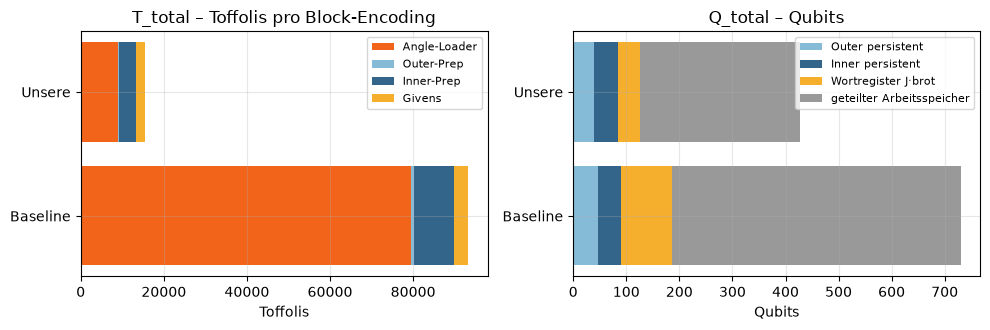

In [14]:
b, o = res["Baseline"], res["Unsere"]
f_lam = b["lambda_eff"] / o["lambda_eff"]
f_T = b["resources"]["toffoli"] / o["resources"]["toffoli"]
f_Q = b["resources"]["qubits"] / o["resources"]["qubits"]
print(f"Verbesserung gesamt: {b['score']/o['score']:.2f}×  =  λ_eff {f_lam:.3f}×  ·  Toffolis {f_T:.2f}×  ·  Qubits {f_Q:.2f}×")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
parts = ["angles_toffoli", "outer_state_prep_toffoli", "inner_state_prep_toffoli", "givens_rotations_toffoli"]
labels = ["Angle-Loader", "Outer-Prep", "Inner-Prep", "Givens"]
for i, (name, r_) in enumerate(res.items()):
    left = 0
    for p, l, col in zip(parts, labels, ["#f26419", "#86bbd8", "#33658a", "#f6ae2d"]):
        v = r_["resources"][p]
        axs[0].barh(name, v, left=left, color=col, label=l if i == 0 else None)
        left += v
axs[0].set(title="T_total – Toffolis pro Block-Encoding", xlabel="Toffolis"); axs[0].legend(fontsize=8)
qparts = ["outer_state_prep_persistent_qubits", "inner_state_prep_persistent_qubits", "angles_persistent_qubits", "temporary_qubits"]
qlabels = ["Outer persistent", "Inner persistent", "Wortregister J·brot", "geteilter Arbeitsspeicher"]
for i, (name, r_) in enumerate(res.items()):
    left = 0
    for p, l, col in zip(qparts, qlabels, ["#86bbd8", "#33658a", "#f6ae2d", "#999999"]):
        v = r_["resources"][p]
        axs[1].barh(name, v, left=left, color=col, label=l if i == 0 else None)
        left += v
axs[1].set(title="Q_total – Qubits", xlabel="Qubits"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lesart:**
- Fast der ganze Gewinn kommt aus **Toffolis** und **Qubits**, kaum aus λ_eff (beide sitzen nahe an den Floors).
- Die Toffolis sanken vor allem bei den **Angle-Loadern** (weniger Zeilen, schlaue Loader) und bei der **Inner-Prep** (hängt über die Kostenformel an R, B, C und brot).
- Der *heuristische* Teil (Outer/Inner/Givens) ist eine fest vorgegebene Kostenformel – man beeinflusst ihn nur über die Form der Faktorisierung. Das können wir direkt durchspielen:

In [15]:
print("Heuristische Kosten (Outer + Inner + Givens) für unsere Form R, B, C bei verschiedenem brot:")
for bits in [6, 7, 8, 10, 12]:
    h = heuristic_costs(N, R, B, C, bits)
    print(f"  brot={bits:2d}: Toffolis {h['toffoli']:6,d}   persistente Qubits {h['persistent_qubits']:4d}"
          f"   temporäre Qubits {h['temporary_qubits']:4d}")
print("\nUnd bei brot = 8 für andere Formen (R, B, C):")
for shape in [(9, 143, 39), (9, 143, 20), (9, 100, 39), (20, 64, 39), (65, 60, 60)]:
    h = heuristic_costs(N, *shape, 8)
    print(f"  {str(shape):15s}: Toffolis {h['toffoli']:6,d}   Qubits {h['qubits']:4d}")

Heuristische Kosten (Outer + Inner + Givens) für unsere Form R, B, C bei verschiedenem brot:
  brot= 6: Toffolis  6,053   persistente Qubits   85   temporäre Qubits  303
  brot= 7: Toffolis  6,353   persistente Qubits   85   temporäre Qubits  303
  brot= 8: Toffolis  6,653   persistente Qubits   85   temporäre Qubits  303
  brot=10: Toffolis  6,153   persistente Qubits   85   temporäre Qubits  606
  brot=12: Toffolis  6,753   persistente Qubits   85   temporäre Qubits  606

Und bei brot = 8 für andere Formen (R, B, C):
  (9, 143, 39)   : Toffolis  6,653   Qubits  388
  (9, 143, 20)   : Toffolis  4,491   Qubits  688
  (9, 100, 39)   : Toffolis  5,075   Qubits  657
  (20, 64, 39)   : Toffolis  6,164   Qubits  629
  (65, 60, 60)   : Toffolis 12,557   Qubits  634


> Die Formel ist **nicht monoton**: Weniger Gewichtssätze C sparen Toffolis, kosten hier aber plötzlich deutlich mehr temporäre Qubits. Solche Sprünge muss man bei jeder Form-Änderung durchrechnen.

## Teil 7 · Hebel und Grenzen – Zusammenfassung

**Was der Chemie-Use-Case in einem Satz macht:** Er komprimiert die 33 Mio. Wechselwirkungszahlen von FeMoCo zu ~1.300 Einheitsvektoren (als 8-Bit-Winkel), lädt diese Winkel mit möglichst billigen reversiblen Lookup-Schaltkreisen und bezahlt dafür mit λ_eff × Toffolis × Qubits pro Block-Encoding-Schritt.

| Stellschraube | Wirkung | Status bei uns |
|---|---|---|
| Fehlerbudget `error_2 ≤ 20 mHa` | Mehr Kompression / weniger Bits | **ausgereizt** (nHa unter der Grenze) |
| `E_gap`-Floor 3,914898 Ha | kleineres λ_eff | **nahe am Floor** |
| Bits pro Winkel (brot) | Wortregister-Qubits, Givens-Kosten, Fehler | 8 Bit; 7 Bit bricht `error_2` |
| Form R, B, C | Tabellenzeilen, Heuristik-Kosten, Λ | R = 9, B = 143, C = 39 |
| Loader-Design (≤ 128 Qubits) | Angle-Toffolis | alle Loader exakt auf 128 Qubits |
| Reihenfolge der Vektoren (Gauge-Symmetrie S₁₄₃) | Tabelle billiger machen | getestet: 25/25 Umordnungen schlechter (Subagent C) |

**Lehre:** Die öffentliche Linie ist in jeder Einzeldimension nahe am Anschlag. Fortschritt kommt nur noch aus *gemeinsamer* Neuoptimierung (Faktorisierung + Wortcodierung + Loader) – das ist teuer und das Feld macht kleine Schritte (T 15.629 → 15.585).

### Übungen
1. **Teil 3:** Ersetze den Baum durch einen reinen Pfad `(0,1),(1,2),…`. Dekodiere dieselben Wörter: Wie ändert sich der Vektor? (Die Wörter gehören zum Baum – Baum und Wörter sind gemeinsam festgelegt.)
2. **Teil 3:** Runde nur die *Ein-Elektron*-Zeilen (0–75) der Baseline auf 8 Bit und lass die Zwei-Elektron-Zeilen bei 12. Welcher Fehler steigt?
3. **Teil 5:** Zähle für `angle_k_0` unserer Familie, wie viele `HMR` es gibt und vergleiche mit der Zahl der `CCX`. Was sagt das über Wiederverwendung von AND-Produkten?
4. **Teil 6:** Wie groß wäre der Score, wenn λ_eff exakt am theoretischen Grenzpaar (Λ = 49, E_gap = 3,914898 → λ_eff ≈ 19,19) läge, bei gleichen T und Q? Warum ist das unrealistisch?